# Apetito de riesgo: concentración de oferentes de crédito

## Resumen

En agosto de 2026, libranza es el producto de mayor saldo agregado y presenta HHI 1.039. El límite de 2.000 es un supuesto ilustrativo; los datos describen oferentes, no clientes de una entidad.

## Contexto y método

La concentración de oferentes por producto sirve como señal de entorno para una conversación de apetito de riesgo. **La cartera de los oferentes no es la cartera propia**: el indicador no mide concentración de clientes, ni límites o decisiones observadas de una entidad. El umbral 2.000 es ilustrativo y no representa un límite aprobado ni una regla regulatoria. Fuente: [SFC, distribución de cartera por producto](https://www.datos.gov.co/Hacienda-y-Cr-dito-P-blico/Distribuci-n-de-cartera-por-producto/rvii-eis8). El producto se selecciona según saldo agregado más alto en el último corte. El HHI está expresado en escala 0–10.000.

In [1]:
from pathlib import Path
import hashlib
import pandas as pd
import matplotlib.pyplot as plt

ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / '03-financial-risk').is_dir()), None)
if ROOT is None:
    raise RuntimeError('Abrir el notebook desde un clon del repositorio.')
plt.rcParams.update({'figure.figsize': (9, 4.4), 'axes.grid': True, 'grid.alpha': .25, 'font.size': 10})


## Datos

Insumo versionado en el repositorio: `03-financial-risk/01-credit-risk/credit-portfolio-strategy/concentracion-hhi-cartera/data/official/hhi_by_product_and_cut.csv`. SHA-256: `8feeabbe14dd786eb9e89b7ca35e187591a70aa226d5ea890233ed4d900892e3`. No se requieren credenciales. La fuente primaria y los procesos de extracción se documentan en el README del companion de origen.

In [2]:
DATA = ROOT / '03-financial-risk/01-credit-risk/credit-portfolio-strategy/concentracion-hhi-cartera/data/official/hhi_by_product_and_cut.csv'
assert hashlib.sha256(DATA.read_bytes()).hexdigest() == '8feeabbe14dd786eb9e89b7ca35e187591a70aa226d5ea890233ed4d900892e3'
print('Archivo y huella verificados:', DATA.name)

Archivo y huella verificados: hhi_by_product_and_cut.csv


## Resultados

La tabla de entrada se valida antes del cálculo; la figura representa los resultados del corte indicado.

In [3]:
df = pd.read_csv(DATA, parse_dates=['fecha_corte'])
assert df[['fecha_corte','unicap','producto','saldo_total','hhi_10000']].notna().all().all()
assert df['hhi_10000'].between(0,10000).all()
latest = df['fecha_corte'].max()
leader = df.loc[df.fecha_corte.eq(latest)].sort_values('saldo_total', ascending=False).iloc[0]
x = df.loc[df.unicap.eq(leader.unicap)].sort_values('fecha_corte').copy()
assert not x.fecha_corte.duplicated().any()
limit = 2000  # supuesto de alerta, no regla oficial
print(f"Producto: {leader.producto}; último corte {latest.date()}; HHI {leader.hhi_10000:.0f}; {len(x)} cortes")
print(f"Cortes con HHI superior al umbral ilustrativo: {(x.hhi_10000 > limit).sum()} de {len(x)}")


Producto: LIBRANZA; último corte 2026-08-31; HHI 1039; 32 cortes
Cortes con HHI superior al umbral ilustrativo: 0 de 32


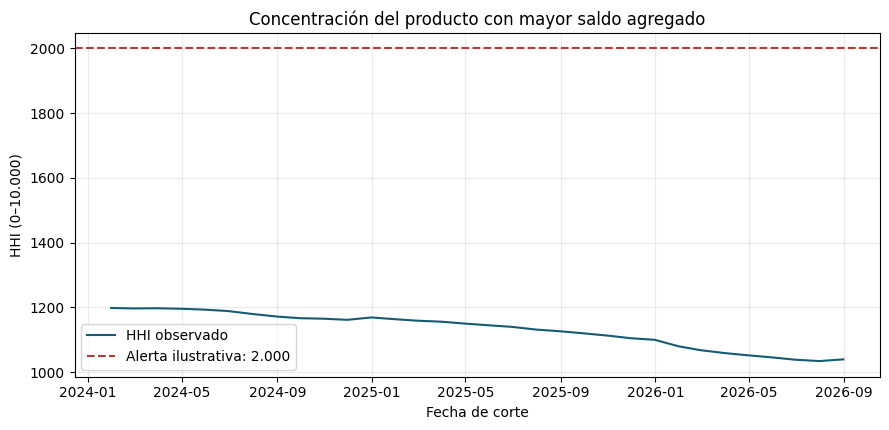

In [4]:
fig, ax = plt.subplots(); ax.plot(x.fecha_corte, x.hhi_10000, label='HHI observado', color='#165a73'); ax.axhline(limit, color='#b13b35', linestyle='--', label='Alerta ilustrativa: 2.000'); ax.set(title='Concentración del producto con mayor saldo agregado', ylabel='HHI (0–10.000)', xlabel='Fecha de corte'); ax.legend(); fig.tight_layout(); plt.show()

## Interpretación y límites

El umbral es una hipótesis de discusión, no una recomendación de límite. La vigilancia de una cartera propia requiere exposiciones por cliente o grupo económico, límites aprobados, excepciones y responsables.

## Control de calidad y comparación entre productos

El cuadro compara todos los productos disponibles en el último corte. El HHI usa saldos por oferente; **no se suman HHI de productos** y la selección por saldo de mercado no equivale a materialidad para una entidad. Si cambia la cobertura de oferentes, la comparación temporal puede cambiar aunque los participantes constantes no cambien.

In [5]:
assert not df.duplicated(['fecha_corte','unicap']).any(), 'Llave corte-producto duplicada'
assert (df.saldo_total > 0).all() and (df.entidades > 0).all()
assert df.participacion_top1.between(0,1).all() and df.participacion_top5.between(0,1).all()
assert (df.participacion_top1 <= df.participacion_top5 + 1e-9).all()
latest_products = df.loc[df.fecha_corte.eq(latest), ['producto','entidades','saldo_total','hhi_10000','participacion_top1']].sort_values('hhi_10000', ascending=False)
print('Productos disponibles en el último corte:',len(latest_products))
latest_products.head(8).round(2)

Productos disponibles en el último corte: 18


,producto,entidades,saldo_total,hhi_10000,participacion_top1
563,LEASING HABITACIONAL VIS UVR,4,4.324326e+11,8048.12,0.89
567,LIBRANZA VIVIENDA NO VIS,7,3.863050e+11,5845.94,0.71
566,LIBRANZA VIVIENDA VIS,7,8.374999e+10,5107.05,0.59
562,LEASING HABITACIONAL VIS PESOS,6,7.506120e+11,4809.36,0.65
565,LEASING HABITACIONAL NO VIS UVR,5,1.586884e+12,4592.60,0.60
564,LEASING HABITACIONAL NO VIS PESOS,12,2.117276e+13,4060.84,0.59
570,CARTERA COMERCIAL LEASING FINANCIERO,14,4.637496e+13,3417.00,0.54
573,MICROCREDITOS < O IGUALES A 25 SMMLV,24,1.801504e+13,2955.25,0.51


La clasificación y la señal cambian con el producto y el umbral elegidos. Esta tabla ayuda a seleccionar qué mercado investigar; no justifica aplicar 2.000 como límite institucional ni identifica concentración por contraparte.

## Literatura y uso del indicador

El [FSB, *Principles for an Effective Risk Appetite Framework* (2013)](https://www.fsb.org/2013/11/cos_131118/) vincula apetito, capacidad, límites y responsabilidades con el negocio y la entidad. El [DOJ, definición de HHI](https://www.justice.gov/atr/herfindahl-hirschman-index) define el índice como suma de cuotas al cuadrado. El número equivalente de oferentes de igual tamaño es `10.000 / HHI`, si el índice utiliza participaciones porcentuales. **No se trasladan umbrales antimonopolio de EE. UU. a límites colombianos.**

## Variante: número equivalente de oferentes

La cantidad equivalente resume la dispersión de saldos en cada producto; no representa el conteo real ni la concentración de los clientes de una entidad. HHI y número equivalente se calculan sobre el universo y el corte disponibles.

In [6]:
comparison=latest_products.copy()
comparison['oferentes_equivalentes']=10000/comparison.hhi_10000.where(comparison.hhi_10000>0)
comparison['cota_hhi_igualdad']=10000/comparison.entidades
assert (comparison.hhi_10000 + 1e-6 >= comparison.cota_hhi_igualdad).all(), 'HHI incompatible con el número de entidades: revisar cobertura'
comparison[['producto','entidades','hhi_10000','oferentes_equivalentes','cota_hhi_igualdad']].head(8).round(2)

,producto,entidades,hhi_10000,oferentes_equivalentes,cota_hhi_igualdad
563,LEASING HABITACIONAL VIS UVR,4,8048.12,1.24,2500.00
567,LIBRANZA VIVIENDA NO VIS,7,5845.94,1.71,1428.57
566,LIBRANZA VIVIENDA VIS,7,5107.05,1.96,1428.57
562,LEASING HABITACIONAL VIS PESOS,6,4809.36,2.08,1666.67
565,LEASING HABITACIONAL NO VIS UVR,5,4592.60,2.18,2000.00
564,LEASING HABITACIONAL NO VIS PESOS,12,4060.84,2.46,833.33
570,CARTERA COMERCIAL LEASING FINANCIERO,14,3417.00,2.93,714.29
573,MICROCREDITOS < O IGUALES A 25 SMMLV,24,2955.25,3.38,416.67
